In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wrds

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- data window -----------------------------------------------------------
# The paper's data starts in 1990. We download from 1988 because the slowest
# features look back 252 days and the MACD normalization looks back another
# 252, so the first ~2 years are "warm-up" and get dropped at the end.
START_DATE = "1988-01-01"

# ---- how contracts are stitched together ----------------------------------
ROLL_BUFFER_DAYS = 5   # never hold a contract within 5 business days of its last safe day
FFILL_LIMIT      = 3   # if a contract is missing a price, carry the last one for at most 3 days

# ---- feature settings (from the paper, Section 2) --------------------------
VOL_SPAN         = 60                      # Exponentially Weighted Moving SD of returns over the past 60 days
VOL_TARGET       = 0.15                    # 15% annual target volatility
RETURN_HORIZONS  = [1, 21, 63, 126, 252]   # day, month, quarter, half year, year
MACD_PAIRS       = [(8, 24), (16, 48), (32, 96)]  # (fast, slow) timescales
WINSORIZE        = True   # clip extreme prices at +/- 5 EWM std (the authors' earlier code does this)


LIB = 'trdstrm' # Futures Library

### Step 1: Connect to WRDS and Explore the Tables

In [2]:
db = wrds.Connection() # Can set username later in a config file

print("Tables:", db.list_tables(library='trdstrm'))

WRDS recommends setting up a .pgpass file.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Tables: ['ds2adj', 'ds2capevent', 'ds2company', 'ds2constdatadly', 'ds2constdatamth', 'ds2constdly', 'ds2constmth', 'ds2ctryqtinfo', 'ds2cusipchg', 'ds2datatype', 'ds2div', 'ds2dps', 'ds2equityindex', 'ds2exchange', 'ds2exchqtinfo', 'ds2fxcode', 'ds2fxrate', 'ds2indexaddldata', 'ds2indexdata', 'ds2indexdatatype', 'ds2indexlist', 'ds2isinchg', 'ds2localcodechg', 'ds2mktval', 'ds2mnemchg', 'ds2numshares', 'ds2primexchqtchg', 'ds2primqtprc', 'ds2primqtri', 'ds2qtnamechg', 'ds2region', 'ds2scdqtprc', 'ds2scdqtri', 'ds2security', 'ds2sedolchg', 'ds2sharehldgs', 'ds2xref', 'dscmcode', 'dscmdesc', 'dscmextval', 'dscminfo', 'dscmitem', 'dscmlicflagcode', 'dscmloc', 'dscmreg', 'dscmval', 'dsfutcalcserextval', 'dsfutcalcserinfo', 'dsfutcalcsermth', 'dsfutcalcserval', 'dsfutclass', 'dsfutcode', 'dsfutcontr', 'dsfutcontrchg', 'dsfutcontrextva

### Step 2: Select the 50 Contracts & Search for ones with an unknown contrcode

In [3]:
# ticker: (contrcode, sector, description)   None = look it up in Step 2b
UNIVERSE = {
    # ---- Commodities (CM) ----
    "CL":   (1986, "CM", "Crude oil WTI"),
    "HO":   (2029, "CM", "Heating oil / ULSD"),
    "NG":   (2060, "CM", "Natural gas"),
    "GC":   (2020, "CM", "Gold"),
    "SI":   (2108, "CM", "Silver"),
    "HG":   (2026, "CM", "Copper"),
    "PL":   (2074, "CM", "Platinum"),
    "PA":   (2065, "CM", "Palladium"),
    "ZC":   (3247, "CM", "Corn"),
    "ZW":   (3272, "CM", "Wheat (Chicago)"),
    "KE":   (3623, "CM", "Wheat (Kansas City)"),
    "ZO":   (3262, "CM", "Oats"),
    "ZR":   (3268, "CM", "Rough rice"),
    "ZL":   (456,  "CM", "Soybean oil"),
    "SB":   (2104, "CM", "Sugar #11"),
    "KC":   (2038, "CM", "Coffee"),
    "CC":   (1980, "CM", "Cocoa"),
    "OJ":   (2036, "CM", "Orange juice"),
    "LE":   (2675, "CM", "Live cattle"),
    "GF":   (3250, "CM", "Feeder cattle"),
    "HE":   (2676, "CM", "Lean hogs"),
    "DC":   (3255, "CM", "Milk class III"),
    "LBS":  (361,  "CM", "Lumber"),
    "GSCI": (None, "CM", "GSCI commodity index"),
    "NR":   (None, "CM", "Rough rice"),
    # ---- Equity indices (EQ) ----
    "SP":   (None, "EQ", "S&P 500 (day session / big contract)"),
    "SC":   (None, "EQ", "S&P 500 composite"),
    "SX5P": (None, "EQ", "Stoxx Europe 50"),
    "ES":   (1381, "EQ", "S&P 500 E-mini"),
    "NQ":   (323,  "EQ", "Nasdaq 100 E-mini"),
    "RTY":  (4396, "EQ", "Russell 2000 E-mini"),
    "YM":   (None, "EQ", "Dow Jones mini"),
    "MD":   (None, "EQ", "S&P MidCap 400"),
    "NK":   (None, "EQ", "Nikkei 225"),
    "CAC":  (None, "EQ", "CAC 40"),
    "FTSE": (None, "EQ", "FTSE 100"),
    "SX5E": (None, "EQ", "Euro Stoxx 50"),
    # ---- Fixed income (FI) ----
    "ZF":   (2680, "FI", "US 5y note"),
    "ZN":   (2682, "FI", "US 10y note"),
    "ZB":   (3271, "FI", "US 30y bond"),
    "BUND": (None, "FI", "German Bund"),
    "BOBL": (None, "FI", "German Bobl"),
    # ---- Currencies (FX) ----
    "6E":   (2683, "FX", "Euro"),
    "6J":   (2846, "FX", "Japanese yen"),
    "6C":   (2776, "FX", "Canadian dollar"),
    "6S":   (2807, "FX", "Swiss franc"),
    "6A":   (None, "FX", "Australian dollar"),
    "6B":   (None, "FX", "British pound"),
    "6M":   (None, "FX", "Mexican peso"),
    "DX":   (None, "FX", "US dollar index"),
}

# Words to search for, for the ones we still need to look up
SEARCH_TERMS = {
    # ---- Commodities ----
    "GSCI": ["GSCI", "GOLDMAN"],
    "NR":   ["ROUGH RICE", "RICE"],
    # ---- Equities ----
    "YM":   ["DOW"],
    "MD":   ["MIDCAP", "400"],
    "SP":   ["S&P 500", "S&P500"],
    "SC":   ["S&P 500", "S&P500"],
    "NK":   ["NIKKEI"],
    "CAC":  ["CAC"],
    "FTSE": ["FTSE 100"],
    "SX5E": ["EURO STOXX", "STOXX 50"],
    "SX5P": ["STOXX EUROPE", "STOXX 50"],
    # ---- Fixed income ----
    "BUND": ["BUND"],
    "BOBL": ["BOBL"],
    # ---- Currencies ----
    "6A":   ["AUSTRALIAN"],
    "6B":   ["BRITISH", "STERLING"],
    "6M":   ["MEXICAN"],
    "DX":   ["DOLLAR INDEX", "USDX"],
}

missing = [t for t, (code, _, _) in UNIVERSE.items() if code is None]
print(f"{len(UNIVERSE) - len(missing)} assets have a code, {len(missing)} still to look up: {missing}")

# Catch any None in UNIVERSE that has no search terms yet
no_terms = [t for t in missing if t not in SEARCH_TERMS]
if no_terms:
    print("No search terms for:", no_terms)

33 assets have a code, 17 still to look up: ['GSCI', 'NR', 'SP', 'SC', 'SX5P', 'YM', 'MD', 'NK', 'CAC', 'FTSE', 'SX5E', 'BUND', 'BOBL', '6A', '6B', '6M', 'DX']


In [4]:
def search_catalog(term, min_contracts=20):
    """Every contract series whose name contains `term`, biggest first."""
    term = term.upper().replace("'", "")
    sql = f"""
        SELECT contrcode,
               MIN(exchtickersymb) AS ticker,
               MIN(contrname)      AS name,
               MIN(isocurrcode)    AS ccy,
               COUNT(*)            AS n_contracts,
               MIN(COALESCE(lasttrddate, startdate)) AS first_date,
               MAX(COALESCE(lasttrddate, startdate)) AS last_date
        FROM {LIB}.wrds_contract_info
        WHERE strpos(UPPER(contrname), '{term}') > 0
        GROUP BY contrcode
        HAVING COUNT(*) >= {int(min_contracts)}
        ORDER BY COUNT(*) DESC
        LIMIT 12
    """
    return db.raw_sql(sql, date_cols=["first_date", "last_date"])

for ticker in missing:
    for term in SEARCH_TERMS.get(ticker, []):
        print(f"\n##### {ticker}  ({UNIVERSE[ticker][2]})   search: '{term}'")
        print(search_catalog(term).to_string(index=False))


##### GSCI  (GSCI commodity index)   search: 'GSCI'
 contrcode ticker                                 name ccy  n_contracts first_date  last_date
    3254.0     GD                S&P GSCI FUTURES COMP USD          384 1992-07-29 2026-09-16
     342.0     GI GSCI (GOLDMAN SACHS COMMODITY INDEX) USD          255 1992-08-05 2015-07-06
    3253.0    GIE              GSCI ER INDEXFUT GLOBEX USD          141 2011-03-15 2027-12-15

##### GSCI  (GSCI commodity index)   search: 'GOLDMAN'
 contrcode ticker                                 name ccy  n_contracts first_date  last_date
     342.0     GI GSCI (GOLDMAN SACHS COMMODITY INDEX) USD          255 1992-08-05 2015-07-06
    1200.0   GOSF                  GOLDMAN SACHS GROUP USD          239 2008-02-15 2028-12-15

##### NR  (Rough rice)   search: 'ROUGH RICE'
 contrcode ticker                    name ccy  n_contracts first_date  last_date
    3268.0     ZR ROUGH RICE COMP FUTURES USD          164 2000-09-20 2027-11-12

##### NR  (Rough rice) 

From above we select the following for having the earlist 

In [5]:
# Codes found with search_catalog
UNIVERSE.update({
    # ---- Commodities ----
    "GSCI": (3254, "CM", "S&P GSCI (formerly Goldman Sachs CI)"),
    "NR":   (379,  "CM", "Rough rice, pit (ends 2016: CME pit closure)"),
    # ---- Equities ----
    "YM":   (None, "EQ", "Dow Jones mini"),          # still to find
    "MD":   (401,  "EQ", "S&P MidCap 400 E-mini"),
    "SP":   (1382, "EQ", "S&P 500 full size"),
    "SC":   (3251, "EQ", "S&P 500 futures"),
    "NK":   (2873, "EQ", "Nikkei 225 (USD composite)"),
    "CAC":  (647,  "EQ", "CAC 40"),
    "FTSE": (1691, "EQ", "FTSE 100"),
    "SX5E": (801,  "EQ", "Euro Stoxx 50 (eurozone)"),
    "SX5P": (1226, "EQ", "Stoxx 50 (all Europe)"),
    # ---- Fixed income ----
    "BUND": (834,  "FI", "German Bund (Eurex)"),
    "BOBL": (704,  "FI", "German Bobl (Eurex)"),
    # ---- Currencies ----
    "6A":   (2744, "FX", "Australian dollar composite"),
    "6B":   (2759, "FX", "British pound composite"),
    "6M":   (2864, "FX", "Mexican peso composite"),
    "DX":   (2000, "FX", "US dollar index"),
})

missing = [t for t, (code, _, _) in UNIVERSE.items() if code is None]
print(f"{len(UNIVERSE)} assets, {len(missing)} still without a code: {missing}")

50 assets, 1 still without a code: ['YM']


### Step 4: Assess Data Quality

Assess whether these are the correct contracts

In [6]:
WINDOW_START = "1990-01-01"   # paper's sample starts here (START_DATE=1988 is warm-up)
WINDOW_END   = "2023-12-31"   # set this to the paper's last date

codes = {t: int(c) for t, (c, _, _) in UNIVERSE.items() if c is not None}
code_list = ", ".join(str(c) for c in sorted(set(codes.values())))

meta = db.raw_sql(f"""
    SELECT contrcode,
           MIN(contrname)      AS name,
           MIN(exchtickersymb) AS exch_ticker,
           MIN(isocurrcode)    AS ccy,
           MIN(currunitcode)   AS unit,
           MIN(ldb)            AS ldb,
           COUNT(*)            AS n_contracts,
           MIN(lasttrddate)    AS first_expiry,
           MAX(lasttrddate)    AS last_expiry
    FROM {LIB}.wrds_contract_info
    WHERE contrcode IN ({code_list})
    GROUP BY contrcode
""", date_cols=["first_expiry", "last_expiry"])

code_to_ticker = {c: t for t, c in codes.items()}
meta["contrcode"] = meta["contrcode"].astype(int)
meta.insert(0, "ticker",  meta["contrcode"].map(code_to_ticker))
meta.insert(1, "my_desc", meta["ticker"].map(lambda t: UNIVERSE[t][2]))
meta.insert(2, "sector",  meta["ticker"].map(lambda t: UNIVERSE[t][1]))
print(meta.sort_values(["sector", "ticker"]).to_string(index=False))

ticker                                      my_desc sector  contrcode                                           name exch_ticker ccy unit ldb  n_contracts first_expiry last_expiry
    CC                                        Cocoa     CM       1980                                          COCOA          CC USD E+00 COM          272   1974-07-22  2028-09-14
    CL                                Crude oil WTI     CM       1986                        CRUDE OIL (LIGHT SWEET)          CL USD E+00 CFA          645   1983-05-18  2037-01-20
    DC                               Milk class III     CM       3255                           MILK CLASS III COMP.          DC USD E+00 CFC          380   1996-04-19  2028-10-03
    GC                                         Gold     CM       2020                                  GOLD (100 OZ)          GC USD E+00 CFD          604   1979-01-26  2032-06-28
    GF                                Feeder cattle     CM       3250                            FEE

Assess how many dates are missing

In [7]:
CACHE = Path("../data/interim/front_check")
CACHE.mkdir(parents=True, exist_ok=True)

# Roll on the trading day (naive rolling to just check for gaps in pricing data)
def front_series(contrcode):
    """Nearest-to-expiry contract's settlement price for every date."""
    sql = f"""
        SELECT DISTINCT ON (f.date_)
               f.date_ AS date, f.futcode, f.settlement
        FROM {LIB}.wrds_fut_contract f
        JOIN (SELECT DISTINCT futcode, lasttrddate
              FROM {LIB}.wrds_contract_info
              WHERE contrcode = {int(contrcode)}) i
          ON f.futcode = i.futcode
        WHERE f.date_ BETWEEN '{START_DATE}' AND '{WINDOW_END}'
          AND f.settlement IS NOT NULL
          AND i.lasttrddate >= f.date_
        ORDER BY f.date_, i.lasttrddate
    """
    return db.raw_sql(sql, date_cols=["date"])

front = {}
for t, c in codes.items():
    path = CACHE / f"{t}.parquet"
    if path.exists():
        front[t] = pd.read_parquet(path)
    else:
        front[t] = front_series(c)
        front[t].to_parquet(path)

In [8]:
bdays = pd.bdate_range(WINDOW_START, WINDOW_END)
n_window = len(bdays)
rows = []

for t, df in front.items():
    have = pd.DatetimeIndex(df["date"]).intersection(bdays)
    row = {"ticker": t, "contrcode": codes[t], "sector": UNIVERSE[t][1]}
    if len(have) == 0:
        rows.append({**row, "first_date": None, "last_date": None,
                     "days_before_listed":        n_window,
                     "prop_window_with_price":    0.0,
                     "days_missing_total":        n_window})
        continue

    first, last = have.min(), have.max()
    trading = bdays[(bdays >= first) & (bdays <= last)]
    is_missing = pd.Series(~trading.isin(have), index=trading)

    # group consecutive missing days into runs ("gaps")
    run_id = (is_missing != is_missing.shift()).cumsum()
    gaps = is_missing[is_missing].groupby(run_id[is_missing]).size()

    days_before   = int((bdays < first).sum())   # contract didn't exist yet
    days_after    = int((bdays > last).sum())    # contract had stopped trading
    days_holes    = int(is_missing.sum())        # no price while it was trading
    days_total    = days_before + days_after + days_holes

    rows.append({
        **row,
        "first_date": first.date(),
        "last_date":  last.date(),
        # ---- share of the window's weekdays with a closing (settlement) price ----
        "prop_window_with_price":    round(len(have) / n_window, 3),
        # ---- counts of missing weekdays ----
        "days_before_listed":        days_before,
        "days_after_delisted":       days_after,
        "days_missing_while_trading": days_holes,
        "days_missing_total":        days_total,
        # ---- % of the asset's OWN trading period (data quality) ----
        "pct_trading_missing_trading_period":       round(100 * is_missing.mean(), 1),
        # ---- gaps ----
        "longest_gap_days":          int(gaps.max()) if len(gaps) else 0,
        "gaps_too_long_to_ffill":    int((gaps > FFILL_LIMIT).sum()),
        "trading_years":             round(len(trading) / 261, 1),
        "missing_per_year_while_trading":   round(days_holes / (len(trading) / 261), 1),
    })

coverage = pd.DataFrame(rows).sort_values(["sector", "ticker"])
print(f"Window: {WINDOW_START} to {WINDOW_END} = {n_window} weekdays\n")

print(coverage[["contrcode", "ticker", "sector", "prop_window_with_price", "first_date", "last_date", "trading_years",
                "days_missing_while_trading", "missing_per_year_while_trading",
                "pct_trading_missing_trading_period",
                "gaps_too_long_to_ffill"]]
      .sort_values(["prop_window_with_price", "missing_per_year_while_trading"], ascending=[True, False])
      .to_string(index=False))

Window: 1990-01-01 to 2023-12-31 = 8870 weekdays

 contrcode ticker sector  prop_window_with_price first_date  last_date  trading_years  days_missing_while_trading  missing_per_year_while_trading  pct_trading_missing_trading_period  gaps_too_long_to_ffill
      4396    RTY     EQ                   0.184 2017-07-10 2023-12-29            6.5                          56                             8.6                                 3.3                       0
      3254   GSCI     CM                   0.482 2006-11-16 2023-12-29           17.1                         193                            11.3                                 4.3                       1
       456     ZL     CM                   0.505 2006-03-30 2023-12-29           17.7                         155                             8.7                                 3.3                       0
      3272     ZW     CM                   0.553 2004-07-16 2023-12-29           19.4                         175             

### Step 5: Build Model Inputs (X) and Targets (y)

Following X-Trend (Wood et al., 2023), Section 2 and Eqs. (1), (4a)-(6):

* **Continuous price (backwards ratio-adjusted, as in the paper).** Our raw closes jump from one contract to the next at every roll. At each roll, ratio = new contract's price / old contract's price on the day before the switch, and every earlier price is multiplied by it. So each day's factor is the product of the ratios of all *later* rolls: the latest `adj_close` equals the real price, and every adjusted daily return equals the held contract's own return.
* **Inputs (8 per day, Eq. 6).** Five vol-scaled returns, $\hat r_{t-t',t} = r_{t-t',t} / (\sigma_t\sqrt{t'})$ for $t' \in \{1, 21, 63, 126, 252\}$, and three MACD signals. Plus `ticker_id` for the learned ticker embedding.
* **Target.** Next-day vol-scaled return, $\tilde r_{t+1} = \frac{\sigma_{tgt}}{\sigma_t} r_{t+1}$. X-Trend-G fits a Gaussian to it, X-Trend-Q fits quantiles, and the Sharpe loss multiplies it by the model's position $z_t \in (-1, 1)$. 

In [9]:
# Front contract per day (same roll rule as data.py), plus that contract's own daily return.
# Computing ret within each futcode BEFORE picking the front means a roll day's return is the
# new contract's move, not the price gap between the old and new contract.
roll_buffer_cal = int(np.ceil(ROLL_BUFFER_DAYS * 7 / 5))   # business -> calendar days

# wrds_fut_contract stores each (futcode, date) several times: dedupe before LAG,
# otherwise LAG compares a row with its own copy and returns 0
adj = db.raw_sql(f'''
    WITH info AS (
        SELECT DISTINCT futcode, contrcode, lasttrddate
        FROM {LIB}.wrds_contract_info
        WHERE contrcode IN ({code_list})
    ),
    f AS (
        SELECT DISTINCT ON (futcode, date_) futcode, date_, settlement
        FROM {LIB}.wrds_fut_contract
        WHERE futcode IN (SELECT futcode FROM info)
          AND date_ BETWEEN '{START_DATE}' AND '{WINDOW_END}'
          AND settlement IS NOT NULL
        ORDER BY futcode, date_
    ),
    px AS (
        SELECT i.contrcode, i.lasttrddate, f.futcode, f.date_, f.settlement,
               f.settlement / NULLIF(LAG(f.settlement) OVER (
                   PARTITION BY f.futcode ORDER BY f.date_), 0) - 1 AS ret
        FROM f JOIN info i ON f.futcode = i.futcode
    )
    SELECT DISTINCT ON (contrcode, date_)
           contrcode, date_ AS date, futcode, settlement AS close, ret
    FROM px
    WHERE lasttrddate >= date_ + {roll_buffer_cal}
    ORDER BY contrcode, date_, lasttrddate
''', date_cols=["date"])

adj["contrcode"] = adj["contrcode"].astype(int)
adj["ticker"] = adj["contrcode"].map(code_to_ticker)
adj["sector"] = adj["ticker"].map(lambda t: UNIVERSE[t][1])
adj = adj.sort_values(["ticker", "date"]).reset_index(drop=True)
adj["ret"] = adj["ret"].astype(float).fillna(0.0)   # first day of the sample

# How much would ignoring rolls distort returns? Compare close-to-close vs within-contract.
naive = adj.groupby("ticker")["close"].pct_change()
is_roll = adj["futcode"] != adj.groupby("ticker")["futcode"].shift()
roll_check = (adj.assign(roll_gap=(naive - adj["ret"]).abs())[is_roll & naive.notna()]
              .groupby("ticker")["roll_gap"].agg(n_rolls="size", mean_gap="mean", max_gap="max"))
print(roll_check.sort_values("mean_gap", ascending=False).head(10).round(4).to_string())

        n_rolls  mean_gap  max_gap
ticker                            
HE          176    0.0766   0.2486
DC          330    0.0575   0.4475
ZO          199    0.0513   0.4524
LBS         214    0.0458   0.2902
SB          150    0.0446   0.8716
NG          411    0.0365   0.5905
ZC          200     0.032   0.2355
NR          165    0.0291   0.3509
LE          238     0.028   0.1387
ZR          140    0.0271   0.2509


In [10]:
# Backwards ratio adjustment (same as data.py's back_adjust).
# ratio at a roll = new contract's close / old contract's close, both on the day before the switch.
# Each day's factor = product of the ratios of all LATER rolls, so the newest prices are untouched.
# This prevents artificial jumps in returns when rolling, while preserving the real return scale 
# between rolls. 
g = adj.groupby("ticker")
is_roll = adj["futcode"] != g["futcode"].shift()
prev_close = g["close"].shift()                   # old contract, day before the roll
new_prev = adj["close"] / (1 + adj["ret"])        # new contract, day before the roll
ratio = pd.Series(np.where(is_roll & prev_close.notna(), new_prev / prev_close, 1.0), index=adj.index)
adj["factor"] = ratio.groupby(adj["ticker"]).transform(
    lambda s: s[::-1].cumprod()[::-1].shift(-1, fill_value=1.0))
adj["adj_close"] = adj["close"] * adj["factor"]

# checks: newest adj_close == real close, and adjusted returns == within-contract returns
last = adj.groupby("ticker").tail(1)
adj_ret = adj.groupby("ticker")["adj_close"].pct_change()
print("latest adj_close == close:", np.allclose(last["adj_close"], last["close"]))
print("max |adj return - contract return|:", f"{(adj_ret - adj['ret']).abs().max():.1e}")

# example: one ticker around its last few rolls
ex = adj[(adj.ticker == "CL") & is_roll].tail(3).index
print(adj.loc[np.r_[[i - 1 for i in ex], ex]].sort_index()
      [["date", "futcode", "close", "ret", "factor", "adj_close"]].to_string())

latest adj_close == close: True
max |adj return - contract return|: 4.4e-16
            date   futcode  close       ret    factor  adj_close
96824 2023-10-13  349340.0  87.69  0.057653  0.987280  86.574549
96825 2023-10-16  275503.0  85.26 -0.012623  1.002600  85.481714
96845 2023-11-13  275503.0  78.26  0.014125  1.002600  78.463511
96846 2023-11-14  352285.0  78.17 -0.000256  1.003498  78.443441
96865 2023-12-12  352285.0  68.61 -0.037998  1.003498      68.85
96866 2023-12-13  352313.0  69.72  0.012636  1.000000      69.72


In [11]:
# ---- settings from the paper (Section 2.2) ---------------------------------
MACD_PRICE_STD_WINDOW = 60    # Eq. 4b: m_t is divided by std of the last 60 prices
MACD_SIGNAL_STD_WINDOW = 252  # Eq. 4a: MACD = m_t / std of the last 252 m_t values
WINSOR_HALFLIFE, WINSOR_SDS = 252, 5   # authors' earlier code, not in the X-Trend paper


def halflife(timescale):
    # Section 2.2: half-life = log(1/2) / log(1 - 1/S)
    return np.log(0.5) / np.log(1 - 1 / timescale)


def build_features(g):
    p = g.set_index("date")["adj_close"]   # backwards ratio-adjusted continuous price

    if WINSORIZE:                   # clip prices more than 5 EWM std from their EWM mean
        ew = p.ewm(halflife=WINSOR_HALFLIFE)
        p = p.clip(ew.mean() - WINSOR_SDS * ew.std(), ew.mean() + WINSOR_SDS * ew.std())

    r = p.pct_change()                                           # Eq. 1, daily
    sigma = r.ewm(span=VOL_SPAN, min_periods=VOL_SPAN).std()     # ex-ante daily vol

    out = pd.DataFrame(index=p.index)
    for h in RETURN_HORIZONS:                                    # Eq. 5
        out[f"ret_{h}"] = p.pct_change(h) / (sigma * np.sqrt(h))
    for S, L in MACD_PAIRS:                                      # Eqs. 4a-4b
        m = (p.ewm(halflife=halflife(S)).mean() - p.ewm(halflife=halflife(L)).mean()) \
            / p.rolling(MACD_PRICE_STD_WINDOW).std()
        out[f"macd_{S}_{L}"] = m / m.rolling(MACD_SIGNAL_STD_WINDOW).std()

    # target: next-day return scaled to VOL_TARGET (sigma annualised so units match)
    out["target"] = r.shift(-1) * VOL_TARGET / (sigma * np.sqrt(252))
    out["sigma"] = sigma            # ex-ante daily vol, kept for portfolio returns later
    return out


FEATURES = [f"ret_{h}" for h in RETURN_HORIZONS] + [f"macd_{S}_{L}" for S, L in MACD_PAIRS]

panel = (adj.groupby("ticker", group_keys=True)[["date", "adj_close"]].apply(build_features)
         .reset_index())
panel["sector"] = panel["ticker"].map(lambda t: UNIVERSE[t][1])
panel["ticker_id"] = panel["ticker"].astype("category").cat.codes   # index for the embedding

# drop the warm-up (needs ~2 years of history) and keep the paper's sample window
panel = (panel.dropna(subset=FEATURES + ["target"])
              .query("@WINDOW_START <= date <= @WINDOW_END")
              .reset_index(drop=True))
panel = panel[["date", "ticker", "ticker_id", "sector", *FEATURES, "target", "sigma"]]
print(f"{len(panel):,} rows, {panel.ticker.nunique()} tickers, "
      f"{panel.date.min().date()} to {panel.date.max().date()}")
panel.head()

362,785 rows, 49 tickers, 1990-01-01 to 2023-12-28


,date,ticker,ticker_id,sector,ret_1,ret_21,ret_63,ret_126,ret_252,macd_8_24,macd_16_48,macd_32_96,target,sigma
0,1990-01-02,6A,0,FX,-1.463576,0.362048,0.856015,1.23529,-0.319812,1.293838,1.357122,1.164446,-0.006727,0.005107
1,1990-01-03,6A,0,FX,-0.716123,0.412159,0.680699,0.943258,-0.365662,1.179959,1.325147,1.164703,0.018191,0.005077
2,1990-01-04,6A,0,FX,1.85387,0.886887,0.895455,1.324011,-0.200501,1.152823,1.309673,1.164760,-0.011797,0.005272
3,1990-01-05,6A,0,FX,-1.231319,0.366712,0.722238,1.081297,-0.255175,1.088804,1.301767,1.181572,0.005052,0.005345
4,1990-01-08,6A,0,FX,0.541784,0.448009,0.609828,1.262314,-0.281076,1.050266,1.295731,1.195700,0.002088,0.005275


In [12]:
# Sanity checks: inputs should be roughly unit-scale, and the target's daily std
# should be near VOL_TARGET / sqrt(252) = 0.0094 if the vol scaling works
print(panel[FEATURES + ["target"]].describe().T[["mean", "std", "min", "max"]].round(3).to_string())
print(f"\ntarget daily std {panel.target.std():.4f}  ->  annualised {panel.target.std() * np.sqrt(252):.3f}"
      f"  (VOL_TARGET = {VOL_TARGET})")

                mean       std        min        max
ret_1       0.015551  0.978312  -5.352472   5.553591
ret_21      0.086967  0.997954  -4.190687   8.491926
ret_63      0.158087  1.025955  -3.903663  10.196411
ret_126     0.224438  1.087137  -5.024003  16.688178
ret_252     0.314596  1.228456  -6.281603  30.154272
macd_8_24   0.133086  1.276837  -8.114314   8.856325
macd_16_48  0.209214  1.775081 -10.504256  11.350306
macd_32_96  0.274764  2.112098 -10.673584    11.5431
target      0.000139  0.009831  -0.183017   0.536685

target daily std 0.0098  ->  annualised 0.156  (VOL_TARGET = 0.15)


### Building the Context Set

X-Trend gives the model a **context set**: a few short sequences from other assets and times, which it compares the target sequence against (Section 3.2). The paper tries three ways to pick them:

* **F, final hidden state:** random sequences of a fixed length (21 or 63 days).
* **T, time-equivalent:** random sequences as long as the target (126 days).
* **C, change-point segmented:** random **regimes** found by Gaussian Process change-point detection (CPD). This worked best in the paper.

The cells below walk through C step by step on one asset, then sample all three types. The code lives in `src/project/features.py`; here we call it and plot what it does.

**Step A: score every day.** For the 21 daily returns ending on day $t$, fit two Gaussian Processes:
* one Matérn 3/2 GP, meaning *one regime*, with likelihood $L_M$
* a change-point GP, meaning *two regimes with a switch at some day $t_{CPD}$*, with likelihood $L_C$

The **severity** $L_C / (L_M + L_C)$ is near 0.5 when one regime explains the data just as well, and near 1 when there is clearly a switch.

In [13]:
import copy
import sys
sys.path.insert(0, str(Path("../src").resolve()))   # so we can import src/project
from project import features as F

cfg = F.load_config()
raw_px = pd.read_parquet(F.ROOT / cfg["raw_path"])        # made by: python -m project.data
feat = pd.read_parquet(F.ROOT / cfg["processed_path"])    # made by: python -m project.features --steps processed
LBW = cfg["cpd"]["lookback"]                              # 21-day lookback window

# British pound, through the June 2016 Brexit vote (the paper's Fig. 3 also uses the pound)
DEMO_TICKER, DEMO_START, DEMO_END = "6B", "2015-06-01", "2016-12-31"
demo_px = raw_px[raw_px.ticker == DEMO_TICKER].set_index("date")["adj_close"]
demo_ret = demo_px.pct_change()
print(f"{DEMO_TICKER}: {demo_px[DEMO_START:DEMO_END].size} trading days in the demo period")

6B: 402 trading days in the demo period


CPD: 402 windows, 1 chunks, 8 workers
  1/1 chunks done
        date ticker  severity  cp_days_back
0 2015-06-01     6B     0.992         5.694
1 2015-06-02     6B     0.887         8.074
2 2015-06-03     6B     0.897         9.020
3 2015-06-04     6B     0.916        10.214
4 2015-06-05     6B     0.940        11.213


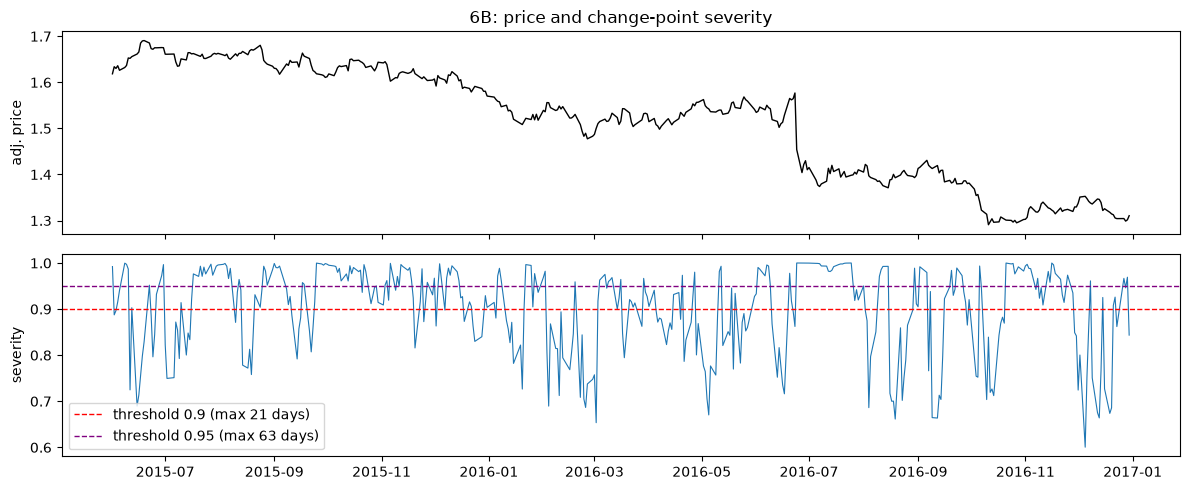

In [14]:
# Severity for every day of the demo period. The full-history scores are in
# data/processed/cpd_scores.parquet (python -m project.features --steps cpd, ~2 hours).
# If that file exists we take the demo period from it, otherwise we compute it here (~1 min).
scores_path = F.ROOT / cfg["cpd_scores_path"]
if scores_path.exists():
    scores_all = pd.read_parquet(scores_path)
    sc = scores_all[(scores_all.ticker == DEMO_TICKER)
                    & scores_all.date.between(DEMO_START, DEMO_END)].reset_index(drop=True)
else:
    demo_cfg = copy.deepcopy(cfg)
    demo_cfg["features"]["sample_start"] = DEMO_START          # only score the demo period
    sc = F.cpd_scores(raw_px[(raw_px.ticker == DEMO_TICKER) & (raw_px.date <= DEMO_END)], demo_cfg)

# cp_days_back: how many days before this day the most likely change sits
print(sc.head().round(3).to_string())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax1.plot(demo_px[DEMO_START:DEMO_END], color="black", lw=1)
ax1.set_ylabel("adj. price")
ax1.set_title(f"{DEMO_TICKER}: price and change-point severity")
ax2.plot(sc.date, sc.severity, lw=0.8)
for seg in cfg["cpd"]["segmentations"]:
    ax2.axhline(seg["threshold"], ls="--", lw=1, color="red" if seg["max_length"] == 21 else "purple",
                label=f"threshold {seg['threshold']} (max {seg['max_length']} days)")
ax2.set_ylabel("severity")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

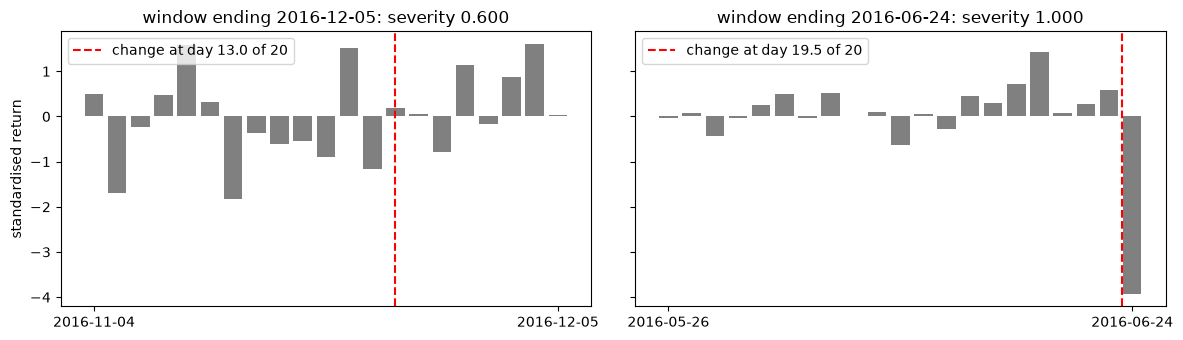

In [15]:
# What the GP sees: the calmest and the most severe window in the demo period.
# Each bar is one day's return, standardised within the window; the dashed line is the
# change location the change-point GP picked.
def show_window(end, ax):
    w = demo_ret[:end].tail(LBW)
    sev, loc = F.cpd_window(w.to_numpy(), cfg["cpd"]["location_starts"])
    ax.bar(range(LBW), (w - w.mean()) / w.std(), color="grey")
    ax.axvline(loc, color="red", ls="--", label=f"change at day {loc:.1f} of {LBW - 1}")
    ax.set_xticks([0, LBW - 1], [w.index[0].date(), w.index[-1].date()])
    ax.set_title(f"window ending {pd.Timestamp(end).date()}: severity {sev:.3f}")
    ax.legend(loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
show_window(sc.loc[sc.severity.idxmin(), "date"], axes[0])
show_window(sc.loc[sc.severity.idxmax(), "date"], axes[1])
axes[0].set_ylabel("standardised return")
plt.tight_layout()
plt.show()

**Step B: cut the history into regimes (Algorithm 1, Appendix A).** Walk backwards from the last day:
* severity $\geq \nu$: a change point. The current regime ends there, and we jump to the day before the change so it isn't blurred into both sides.
* otherwise the regime grows by a day, until it reaches the max length, where it is cut anyway.
* regimes shorter than $l_{min} = 5$ days are dropped.

The paper uses two settings: $\nu = 0.9$ with max 21 days, and $\nu = 0.95$ with max 63 days. Below is a plain copy of the algorithm, checked against the one in `features.py`.

In [16]:
def segment(sev, back, threshold, l_min, l_max):
    """Algorithm 1. sev / back: severity and cp_days_back per day, in date order.
    Returns (start, end) row positions of each regime, both inclusive."""
    t = t1 = len(sev) - 1            # t: day being looked at, t1: end of the regime being built
    regimes = []
    while t >= 0:
        if sev[t] >= threshold:      # the window ending at t has a change point
            tc = t - back[t]         # where it is
            t0 = max(int(np.ceil(tc)), 0)
            if t1 - t0 >= l_min:     # keep the regime unless it is too short
                regimes.append((t0, t1))
            t = int(np.floor(tc)) - 1    # carry on from the day before the change
            t1 = t
        else:                        # no change: the regime grows by one day
            t -= 1
            if t1 - t == l_max and t >= 0:   # max length reached: cut here
                regimes.append((t, t1))
                t1 = t
    return regimes[::-1]

L_MIN = cfg["cpd"]["min_length"]
demo_regimes = {}
for seg in cfg["cpd"]["segmentations"]:
    args = (sc.severity.to_numpy(), sc.cp_days_back.to_numpy(), seg["threshold"], L_MIN, seg["max_length"])
    mine = segment(*args)
    assert mine == F.segment_regimes(*args), "notebook copy differs from features.py"
    demo_regimes[seg["max_length"]] = pd.DataFrame(
        [(sc.date[a], sc.date[b], b - a + 1) for a, b in mine], columns=["start", "end", "days"])

print("max 21 days, threshold 0.9, first regimes:")
print(demo_regimes[21].head(8).to_string())

max 21 days, threshold 0.9, first regimes:
       start        end  days
0 2015-06-01 2015-06-11     9
1 2015-06-15 2015-07-13    20
2 2015-07-15 2015-08-11    20
3 2015-08-13 2015-08-20     6
4 2015-08-24 2015-09-16    17
5 2015-09-18 2015-10-13    18
6 2015-10-15 2015-11-10    19
7 2015-11-12 2015-11-30    12


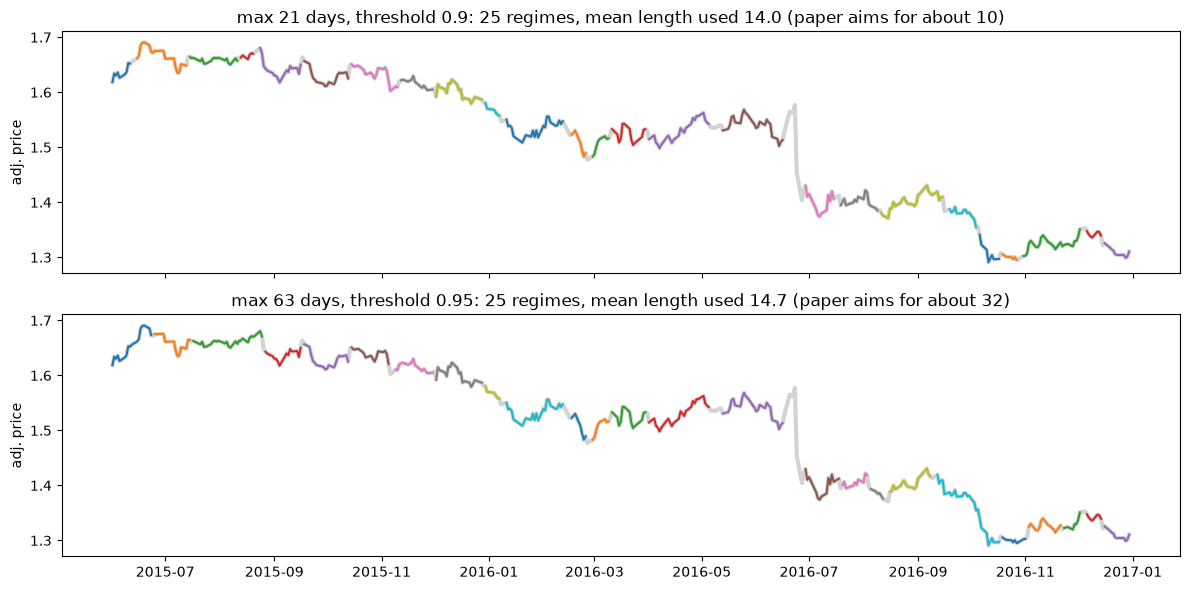

In [17]:
# Like the paper's Fig. 3: each colour is one regime (white gaps: change-point days
# and dropped short regimes)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (L, reg) in zip(axes, demo_regimes.items()):
    ax.plot(demo_px[DEMO_START:DEMO_END], color="lightgrey", lw=3)
    for k, r in reg.iterrows():
        ax.plot(demo_px[r.start:r.end], color=plt.cm.tab10(k % 10), lw=1.5)
    thr = next(s["threshold"] for s in cfg["cpd"]["segmentations"] if s["max_length"] == L)
    used = reg.days.clip(upper=L)    # the sampler keeps at most L days of each regime
    ax.set_title(f"max {L} days, threshold {thr}: {len(reg)} regimes, "
                 f"mean length used {used.mean():.1f} (paper aims for about {L / 2:.0f})")
    ax.set_ylabel("adj. price")
plt.tight_layout()
plt.show()

**Step C: sample context sets.** Contexts are drawn **at training time**, fresh for every target in every mini-batch, by `ContextSampler`. Nothing below is saved. Each context is a sequence of the 8 inputs **plus** `target` (the paper also gives the model the contexts' next-day returns), padded at the front so the last real day is always the final step.

At test time `before=` the target's date makes every context end before it, so no future data is used. Here the sampler uses all 49 assets for F and T. C uses the full regimes file if the CPD run has finished, otherwise just the demo regimes above.

In [18]:
regimes_path = F.ROOT / cfg["regimes_path"]
if regimes_path.exists():
    regimes = pd.read_parquet(regimes_path)
else:                                    # only the demo asset and period
    regimes = F.cpd_regimes(sc, cfg)

sampler = F.ContextSampler(feat, regimes, cfg)
rng = np.random.default_rng(0)
BEFORE = DEMO_END                        # pretend the target is on the last demo day
ctx = {"F (21 days)": sampler.final_hidden(10, 21, before=BEFORE, rng=rng),
       "T (126 days)": sampler.time_equivalent(10, before=BEFORE, rng=rng),
       "C (regimes, max 21)": sampler.cpd(10, 21, before=BEFORE, rng=rng)}

for name, c in ctx.items():
    print(f"{name}: x {c['x'].shape} = (contexts, days, 8 inputs + target), "
          f"real days per context {c['mask'].sum(1).min()}-{c['mask'].sum(1).max()}")

c = ctx["C (regimes, max 21)"]
print(pd.DataFrame({"ticker": c["ticker"], "start": pd.to_datetime(c["start"]).date,
                    "end": pd.to_datetime(c["end"]).date, "real days": c["mask"].sum(1)}).to_string())

F (21 days): x (10, 21, 9) = (contexts, days, 8 inputs + target), real days per context 21-21
T (126 days): x (10, 126, 9) = (contexts, days, 8 inputs + target), real days per context 126-126
C (regimes, max 21): x (10, 21, 9) = (contexts, days, 8 inputs + target), real days per context 7-21
  ticker       start         end  real days
0     6B  2016-06-29  2016-07-15         12
1     6B  2015-11-12  2015-11-30         12
2     6B  2016-02-29  2016-03-09          8
3     6B  2015-06-01  2015-06-11          9
4     6B  2016-09-19  2016-10-04         12
5     6B  2016-05-18  2016-06-16         21
6     6B  2016-12-16  2016-12-30         10
7     6B  2016-10-19  2016-10-27          7
8     6B  2015-07-15  2015-08-11         20
9     6B  2016-07-19  2016-08-09         16


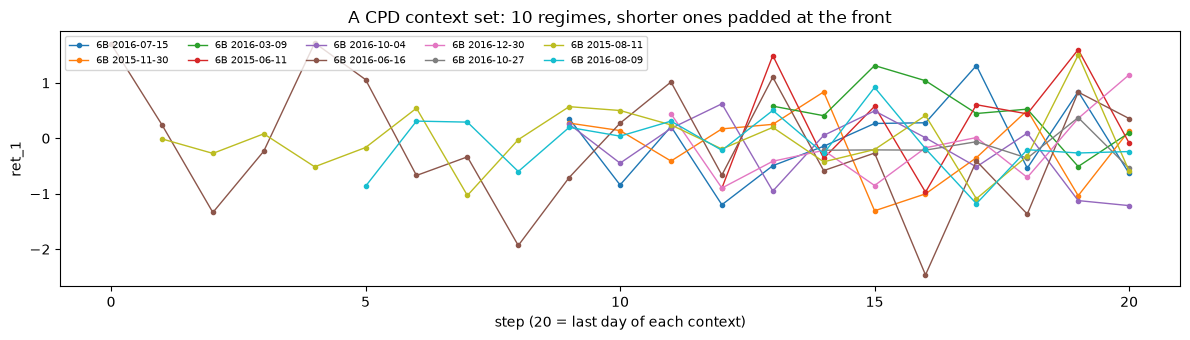

In [19]:
# One CPD context set: the vol-scaled 1-day return (input) of each regime, right-aligned.
# Padding days (mask False) are left out of the plot.
c = ctx["C (regimes, max 21)"]
k_ret1 = F.feature_columns(cfg).index("ret_1")
fig, ax = plt.subplots(figsize=(12, 3.5))
for i in range(len(c["x"])):
    m = c["mask"][i]
    ax.plot(np.flatnonzero(m), c["x"][i, m, k_ret1], marker=".", lw=1,
            label=f"{c['ticker'][i]} {pd.Timestamp(c['end'][i]).date()}")
ax.set_xticks(range(0, c["x"].shape[1], 5))
ax.set_xlabel("step (20 = last day of each context)")
ax.set_ylabel("ret_1")
ax.set_title("A CPD context set: 10 regimes, shorter ones padded at the front")
ax.legend(ncol=5, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()